In [2]:
import torch
import torch.nn as nn


A essência do machine learning e do deep learning é pegar algum dado do passado, e construir um algorítmo (como uma rede neural) para descobrir padrões nele e usar esses padrões descobertos para prever o futuro.

Existem muitas formas de fazer isso, e muitas outras formas estão sendo descobertas ao longo do tempo.

Mas e se começarmos com uma linha reta ?

Vamos ver se podemos construir um modelo no PyTorch que descubra os padrões dessa linha reta e o reproduza.

O que vamos cobrir nesse notebook ?

|Tópico|Conteúdo|
|---|---|
|Preparar os dados|Os dados podem ser qualquer coisa, mas para começar, vamos criar uma linha reta simples|
|Construindo um modelo|Aqui vamos criar um modelo para aprender os padrões nos dados, vamos também escolher uma função de perda, otimizar e construir um ciclo de treino|
|Ajustando o modelo aos dados (treinamento)|Conseguimos os dados e o modelo, agora vamos deixar o modelo encontrar os padrões nesses dados|
|Fazendo predições e avaliando o modelo|Nosso modelo encontrou padrão nos dados, vamos comparar isso com os dados reais|
|Salvando e carregando o modelo|Você vai querer usar seu modelo em qualquer lugar, ou voltar para ele depois|
|Testando tudo junto|Vamos pegar tudo acima e combinar|

#Preparando os dados

Para começar, vamos enfatizar que os "dados" em machine learning podem significar tudo que podemos imaginar. Uma tabela de números, como uma grande planilha do excel, imagens de qualquer tipo, vídeos, arquivos de audio, estruturas proteícas, texto e muito mais.

Machine learning é um jogo de duas partes ;

1. Tornar seus dados, seja lá o que for, em números (representação)
2. Pegar ou construir um modelo para aprender a representação da melhor forma possível

Mas caso não tenhamos dados, nós podemos criar alguns nós mesmos.

Vamos utilizar regressão linear para criar dados com parâmetros conhecidos(coisas que podem ser aprendidas por um modelo) e então podemos usar o PyTorch para construir modelos que conseguem estimar esses parametros usando gradiente descendente.

In [3]:
#criando parametros *conhecidos*

peso = 0.7
vies = 0.3

#criando os dados

start = 0
end = 1
step = 0.02
x = torch.arange(start, end, step).unsqueeze(dim=1)
y = peso * x + vies

x[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

Agora vamos começar a criar um modelo que pode aprender a relação entre X (features) e Y (rótulos)

# Dividir os dados em conjuntos de treinamento e teste

Conseguimos alguns dados, mas antes de construir um modelo, precisamos dividir esses dados.

Um dos passos mais importantes em projetos de machine learning é criar conjuntos de treinamento e de teste (e quando necessário, um conjunto de validação).

Cada divisão no conjunto de dados serve para um propósito específico:

|Divisão|Propósito|Quantia total de dados|Quão frequentemente é usado?|
|---|---|---|---|
|Conjunto de treinamento|O modelo aprende por esses dados|~60-80%|Sempre|
|Conjunto de validação|O modelo é ajustado com esses dados(Como uma prova prática que você faz antes do exame final)|~10-20%|Frequentemente, mas não sempre|
|Conjunto de teste|O modelo é avaliado com esses dados, para saber o que ele aprendeu(Como a prova final que você faz ao fim do semestre)|~10-20%|Sempre

Por agora, vamos usar apenas um conjunto de treino e de teste. Isso significa que temos um conjunto para o nosso modelo aprender e também ser avaliado.

Podemos crialos divindo nosso `x` e `y`

In [4]:
#criando a divisão de treino/teste

train_split = int(0.8 * len(x))
x_train, y_train = x[:train_split], y[:train_split]
x_test, y_test = x[train_split:], y[train_split:]

len(x_train), len(y_train), len(x_test), len(y_test)

(40, 40, 10, 10)

Agora temos 40 amostras para treinamento (`x_$train` e `y_train`) e 10 amostras para o teste (`x_test` e `y_test`)

Mas agora, nossos dados são apenas números em uma página, vamos criar uma função para visualizar eles

In [5]:
import matplotlib.pyplot as plt

def plot_predictions(train_data=x_train,
                     train_labels=y_train,
                     test_data=x_test,
                     test_labels=y_test,
                     predictions=None):
  """
  Gera gráfico com os dados de treino e teste, e compara as predições com os dados reais.
  """
  plt.figure(figsize=(10, 7))

  # Desenha os dados de treino em azul
  plt.scatter(train_data, train_labels, c="b", s=4, label="Dados de treino")

  # Desenha os dados de teste em verde
  plt.scatter(test_data, test_labels, c="g", s=4, label="Dados de teste")

  if predictions is not None:
    plt.scatter(test_data, predictions, c="r", s=4, label="Predições")

  # mostra o gráfico
  plt.legend(prop={"size": 14})
  plt.show()

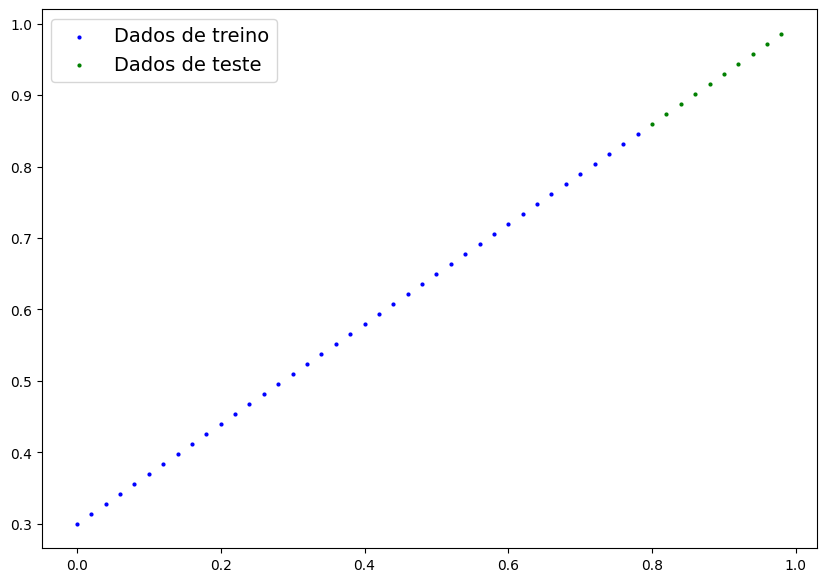

In [6]:
plot_predictions()

#Construindo um modelo

Agora que temos alguns dados, vamos construir um modelo parar usar os pontos azuis para prever os pontos verdes.

In [7]:
#Criando a classe de um modelo de regressão linear
class ModeloRegressaoLinear(nn.Module): #<- quase tudo no PyTorch é um nn.Module(pense nisso como blocos de lego)
  def __init__(self):
    super().__init__()
    self.pesos = nn.Parameter(torch.randn(1, #<-começa com pesos aleátorios(vai se ajustar conforme o modelo aprende)
                                          dtype=torch.float), #<- PyTorch vai usar float32 como padrão
                              requires_grad=True)
    self.vies = nn.Parameter(torch.randn(1, #<-começa com vieses aleátorios(vai se ajustar conforme o modelo aprende)
                                        dtype=torch.float), #<- PyTorch vai usar float32 como padrão
                              requires_grad=True)
    #O parâmetro forward define o calculo do modelo
  def forward(self, x: torch.Tensor) -> torch.Tensor:  #<- "x" é o dado de entrada
    return self.pesos * x + self.vies #<- essa é a formula da regressão linear (y = m*x + b)

O `requires_grad=True` é o gradiente descendente, é ele que diz que o PyTorch pode deixar a máquina trabalhar.

- Se o `requires_grad=False`: O tensor é um número estático, uma constante congelada. Se você fizer as contas com ele, o PyTorch processa o resultado e joga o histórico fora. Se o gradiente descendente tentar trabalhar ali, ele dá de cara com uma porta fechada, porque não tem nenhum histórico pra ele trabalhar.
- Se o `requires_grad=True`: O PyTorch liga o gravador (o sistema de Autograd) e começa a desenhar um grafo computacional. Cada operação matemática que você faz com esse tensor vira um nó em uma árvore de histórico.

Quando chegar a hora do gradiente rodar, ele olha pra esse grafo do histórico construido pelo `requires_grad`, percorre o caminho de trás pra frente calculando as derivadas, e descobre exatamente quanto o peso e o viés precisam mudar.

Sem esse parâmetro ativado, o otimizador não tem "rastro" pra seguir, e não consegue atualizar nada.

##Fundamentos da construção de modelos no PyTorch

PyTorch tem aproximadamente 4 módulos essênciais que você pode usar para criar qualquer tipo de modelo que você possa imaginar.

Eles são: `torch.nn`,`torch.optim`,`torch.utils.data.dataset` e `torch.utils.data.Dataloader`. Por enquanto vamos focar apenas nos dois primeiros

|Módulo PyTorch|O que ele faz?|
|---|---|
|`toch.nn`|Contem todos os blocos de montar para grafos computacionais(uma série de cálculos executados de uma maneira específica).|
|`torch.nn.Parameter`|Armazena tensores que podem ser usados com `nn.Module`. Se `requires_grad=True` os gradientes são calculados automáticamente, isso geralmente é chamado de autograd.|
|`torch.nn.Module`|A classe base para todos os módulos de redes neurais, todos os blocos de construir de redes neurais são sub-classes. Se você está construindo a rede neural em PyTorch, seu modelo precisa de sub-classe `nn.Module`. Precisa de um método `forward()` para ser implementado.
|`torch.optim`|Contém vários algoritmos de otimização.|
|`def forward()`|Todas as sub-classe `nn.Modules` precisam de um método `forward()`, isso define o calculo que será realizado nos dados passados.


De forma mais simples ;
- `nn.Module` contém os grandes blocos de montar (camadas)
- `nn.Parameter` contém os pequenos parâmetros, como peso e vieses.
- `forward()` conta ao bloco grande como fazer calculos nas entradas
- `torch.optim` contém métodos de otimização

Agora que tiramos isso do caminho, vamos criar uma instância do modelo com a classe que fizemos, e checar seus parametros usando `.parameters()`

In [8]:
#Vamos colocar uma seed manualmente, já que o nn.Parameter é iniciado aleatóriamente
torch.manual_seed(42)

#criamos uma instância do modelo
model_0 = ModeloRegressaoLinear()

#checando os parâmetros do modelo

list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

Nós também podemos conseguir o estado do modelo (o que o modelo contém) usando `.state_dict()`

In [9]:
model_0.state_dict()

OrderedDict([('pesos', tensor([0.3367])), ('vies', tensor([0.1288]))])

Essencialmente, queremos começar com parâmetros aleatórios e fazer com que o modelo os atualize para parâmetros que melhor se ajustem aos nossos dados

##Fazendo predições com `torch.inference_mode()`

Para verificar isso, podemos passar os dados de teste x_test para ver o quão bem ele prevê o resultado y_test.

Quando passamos dados para o nosso modelo, eles passam pelo método forward()  do modelo e produzem um resultado usando o cálculo que definimos.

Vamos fazer algumas previsões.

In [10]:
# Make predictions with model
with torch.inference_mode():
    y_preds = model_0(x_test)

O método `torch.inference_mode` é um gerenciador de contexto especializado, ou seja, ele serve apenas para aquele bloco, ele abre o modelo, usa e fecha. A ideia aqui é desativar uma série de recursos, como o gradiente descendente para deixar o modelo mais rápido. Assim estamos realmente testando o modelo, e não esperando treinamento. Com isso gastamos menos poder computacional e o modelo roda muito mais rápido.

In [11]:
#verificando as predições
print(f"Número de amostras de teste: {len(x_test)}")
print(f"Número de previsões feitas: {len(y_preds)}")
print(f"Previsões: \n{y_preds}")

Número de amostras de teste: 10
Número de previsões feitas: 10
Previsões: 
tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])



Observe que há um valor de previsão para cada amostra de teste.

Isso ocorre devido ao tipo de dados que estamos usando. Para nossa linha reta, um valor X corresponde a outro valor Y.

No entanto, os modelos de aprendizado de máquina são muito flexíveis. Você pode ter 100 valores X mapeados para um, dois, três ou 10 valores Y. Tudo depende do que você está trabalhando.

Nossas previsões ainda são números em uma página; vamos visualizá-las com a `plot_predictions()` função que criamos acima.

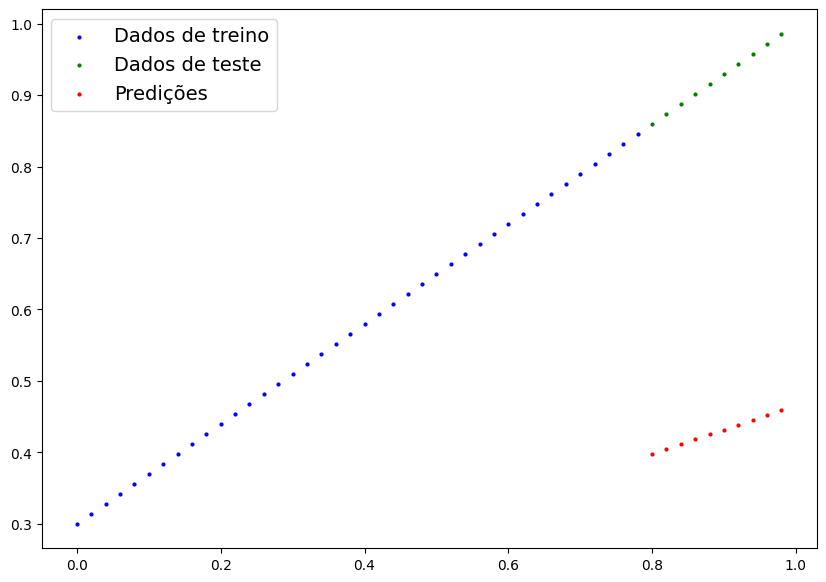

In [12]:
plot_predictions(predictions=y_preds)

In [13]:
y_test - y_preds

tensor([[0.4618],
        [0.4691],
        [0.4764],
        [0.4836],
        [0.4909],
        [0.4982],
        [0.5054],
        [0.5127],
        [0.5200],
        [0.5272]])

#Treinando o modelo

Agora nosso modelo faz previsões usando parâmetros aleátorios para fazer cálculos, ele está básicamente chutando.

Para corrigir isso, podemos atualizar os seus parâmetros internos: os valores que definimos aleátoriamente usando `nn.Parameter()` e `torch.randn()` para ser algo que represente melhor os dados.

Podemos hard codar isso (desde que nós sabemos que os valores padrões são `peso=0.7` e `vies=0.3`) mas qual a graça de fazer isso ?

Ao invés disso, podemos escrever código para ver se o modelo consegue descobrir isso por sí mesmo.

## Criando uma função de perda e omitização no PyTorch

Para nosso modelo atualizar seus parâmetros por sí mesmo, precisamos adicionar algumas outras coisas na receita

E isso é a função de perda e um otimizador.

O papel de cada uma é a seguinte :

|Função|O que faz|Onde reside no PyTorch|Valores comuns|
|---|---|---|---|
|Função de perda|Calcula o quão errado as previsões do nosso modelo(`y_preds`)<br> são comparados aos rotulos reais(`y_test`).Menor é melhor.|PyTorch possuí diversas funções de perda integradas ao `torch.nn`|Média de erro absoluto(MAE) para problemas de regressão(`torch.nn.L1Loss()`)<br> e Entropia cruzada binária para problemas de classificação binária(`torch.nn.BCELoss()`.|
|Otimizador|Diz ao seu modelo como atualizar seus parâmetros internos para <br>minimizar a perda|PyTorch possuí diversas funções otimizadoras integradas ao `torch.optimize`|Gradiente descendente estocástico (`torch.optim.SGD()`) Adam optimize(`torch.optim.Adam()`)

Vamos criar uma função de perda e um otimizador que podemos usar para ajudar a melhorar nosso modelo.

A sua função de perda e seu otimizador vão depender do tipo de problema que você está trabalhando.



Para nosso problema, como estamos prevendo um número, vamos usar MAE no PyTorch como nossa função de perda.

*A média de erro abosluta calcula a diferença a diferença absoluta entre dois pontos(previsão e rótulos) e pega uma média entre todos os exemplos*

E como otimizador, vamos usar o SGD onde:

- `params` são os parâmetros do modelo que queremos otimizar (como os pesos e o vies, valores que definimos aleatóriamente antes)
- `lr` é a frequência de aprendizado, onde você diz quanto você gostaria que o otimizador atualizasse os parâmetros, alto significa que o otimizador vai tentar fazer grandes atualizações(ás vezes pode ser muito grande, e o otimizador pode falhar), baixo significa que o otimizador vai fazer pequenas atualizações(ás vezes podem ser tão pequenas que o que o otimizador demora muito tempo para encontrar os valores ideais). A taxa de aprendizagem é considerado um **hyper-parâmetro** porque depende de um engenheiro de machine learning para ser definido. Normalmente começamos com valores de `0.01`, `0.001`, `0.0001`. De qualquer forma isso pode ser alterado a qualquer momento.



In [14]:
#Criando a função de perda
loss_fn = nn.L1Loss() #L1Loss é o mesmo que MAE

#Criando o otimizador
optimizer = torch.optim.SGD(params=model_0.parameters(),
                                   lr=0.01)

## Loop de otimização (Loop de treino)

Agora que temos uma função de ferde e de otimização, podemols criar o **loop de teste**.

O loop de treino envolve o modelo analisar os dados de treinamento, e aprendendo a relação deles com as `features` e os `rótulos`.

O loop de teste envolve analisarmos os dados de teste, e avaliar o quão bom são os padrões que o modelo aprendeu com os dados de treino (o modelo nunca vê os dados de teste durante o treino)

É chamado de loop porque queremos que o modelo olhe para cada amostra do nosso datasetm

## PyTorch Loop de treino

Para o loop de treino, vamos construir os seguintes passos :

|Etapa|Passo|O que faz?|Exemplo de código|
|---|---|---|---|
|1|Forward Pass|O modelo passa por todos os dados de treino,<br> executando os cálculos da função `forward()`|`model(x_train)`|
|2|Calculando a perda|A saída do modelo (previsões) são comparadas<br> com a realidade, e avaliadas pra ver o quão erradas<br> estão|`loss = loss_fn(y_preds, ytrain)`
|3|Gradiente zero|O gradiente otimizador é definido em zero<br> porque se o gradiente anterior calculou um ajuste<br> de `+0.5` e você não zera, na próxima volta ele vai<br> somar o novo cálculo (`+3`) com o lixo anterior<br> (`+0.5`), resultando em uns malucos `+3.5`.|`optimizer.zero_grad()`|
|4|Roda o bakpropagation (`backward`) na perda|Calcula o gradiente da perda, respeitando todos os parâmetros<br> com `requires_grad=True`|`loss.backward()`|
|5|Atualiza o otimizador|Atualiza os parâmetros que tem o `requires_grad=True`<br> usando os gradientes calculados para reduzir futura perda|`optimizer.step()`|

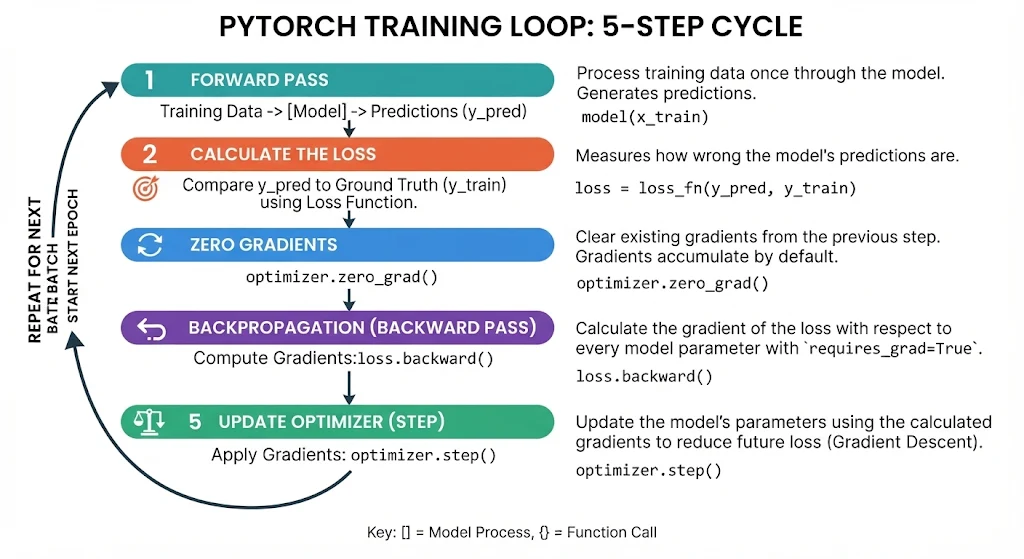

## PyTorch Loop de teste

|Etapa|Passo|O que faz?|Exemplo de código|
|---|---|---|---|
|1|Forward Pass|O modelo passa por todos os dados de treino, executando os cálculos da função forward()|`model(x_text)`|
|2|Calcula a perda|A saída do modelo (previsões) são comparadas com a realidade, e avaliadas pra ver o quão <br> erradas estão|`loss = loss_fn(y_pred, y_test)`|
|3|Calcula as métricas de avaliação|Além do valor da perda, você pode querer calcular outras métricas de avaliação, como a precisão<br> no conjunto de teste.|`Funções personalizadas`|

No loop de teste, não executamos o backpropagation (`loss_backward()`) e nem a otimização (`optimizer_step()`) isso é porque não queremos que os parâmetros mudem durante o teste, eles já foram calculados. Para o teste, nós apenas estamos interessados na saída do Forward Pass do modelo.